# 网络源码

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

In [5]:
# 位置编码（Positional Encoding）
# 使用正弦 / 余弦函数为序列注入位置信息，与原始论文一致。
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        # 计算位置编码
        position = torch.arange(max_len).unsqueeze(1)  # [max_len, 1]
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))

        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)  # 偶数位置用sin
        pe[:, 0, 1::2] = torch.cos(position * div_term)  # 奇数位置用cos

        self.register_buffer('pe', pe)  # 注册为buffer，不参与梯度更新

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: [seq_len, batch_size, d_model]
        """
        x = x + self.pe[:x.size(0)]
        return self.dropout(x)

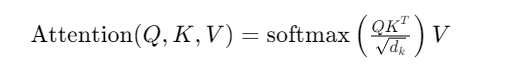

In [6]:
# 缩放点积注意力（Scaled Dot-Product Attention）
def scaled_dot_product_attention(
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    mask: torch.Tensor = None
) -> tuple[torch.Tensor, torch.Tensor]:
    """
    query, key, value: [batch_size, num_heads, seq_len, d_k]
    mask: 可选，[seq_len, seq_len] 或 [batch_size, 1, seq_len, seq_len]
    """
    d_k = query.size(-1)

    # Q * K^T / sqrt(d_k)
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)

    # 应用mask（将需要mask的位置设为极小值，softmax后趋近于0）
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)

    attn_weights = F.softmax(scores, dim=-1)

    # 乘以Value
    output = torch.matmul(attn_weights, value)

    return output, attn_weights

In [7]:
# 多头注意力（Multi-Head Attention）
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int):
        super().__init__()
        assert d_model % num_heads == 0, "d_model 必须能被 num_heads 整除"

        self.d_k = d_model // num_heads
        self.num_heads = num_heads

        # 三个线性变换层 + 输出线性层
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

        self.attn_weights = None

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        batch_size = q.size(0)

        # 线性投影并拆分为多头: [batch, seq_len, d_model] -> [batch, heads, seq_len, d_k]
        query = self.w_q(q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        key   = self.w_k(k).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        value = self.w_v(v).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # 缩放点积注意力
        attn_output, self.attn_weights = scaled_dot_product_attention(query, key, value, mask)

        # 拼接多头: [batch, heads, seq_len, d_k] -> [batch, seq_len, d_model]
        attn_output = attn_output.transpose(1, 2).contiguous().view(batch_size, -1, self.num_heads * self.d_k)

        # 输出线性层
        output = self.w_o(attn_output)

        return output

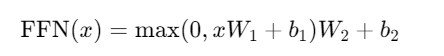

In [8]:
# 前馈神经网络（Position-wise Feed-Forward Network）
class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.ReLU()  # 原文用ReLU

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear2(self.dropout(self.activation(self.linear1(x))))

In [9]:
# 编码器层（Encoder Layer）
# 每个编码器层包含：多头自注意力 + 残差连接 + LayerNorm + 前馈网络 + 残差连接 + LayerNorm
class EncoderLayer(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        # 自注意力子层 + 残差 + Norm
        attn_output = self.self_attn(x, x, x, mask)
        x = self.norm1(x + self.dropout1(attn_output))

        # 前馈子层 + 残差 + Norm
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_output))

        return x

In [10]:
# 解码器层（Decoder Layer）
# 每个解码器层包含：掩码多头自注意力 + 残差 Norm + 编码器 - 解码器注意力 + 残差 Norm + 前馈网络 + 残差 Norm
class DecoderLayer(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads)       # 掩码自注意力
        self.cross_attn = MultiHeadAttention(d_model, num_heads)      # 编码器-解码器注意力
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(
        self,
        x: torch.Tensor,
        enc_output: torch.Tensor,
        self_mask: torch.Tensor = None,
        cross_mask: torch.Tensor = None
    ) -> torch.Tensor:
        # 1. 掩码自注意力
        attn_output = self.self_attn(x, x, x, self_mask)
        x = self.norm1(x + self.dropout1(attn_output))

        # 2. 编码器-解码器注意力（Q来自解码器，K/V来自编码器输出）
        cross_output = self.cross_attn(x, enc_output, enc_output, cross_mask)
        x = self.norm2(x + self.dropout2(cross_output))

        # 3. 前馈网络
        ff_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout3(ff_output))

        return x

In [11]:
# 完整编码器
class Encoder(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        num_layers: int,
        num_heads: int,
        d_ff: int,
        max_len: int = 5000,
        dropout: float = 0.1
    ):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.d_model = d_model

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        """
        x: [batch_size, seq_len]  token索引
        """
        # 嵌入 + 缩放（原文乘以sqrt(d_model)）
        x = self.token_emb(x) * math.sqrt(self.d_model)
        # 位置编码需要 [seq_len, batch, d_model] 输入
        x = x.transpose(0, 1)
        x = self.pos_enc(x)
        x = x.transpose(0, 1)  # 换回 [batch, seq_len, d_model]

        for layer in self.layers:
            x = layer(x, mask)

        return x

In [12]:
# 完整解码器
class Decoder(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        num_layers: int,
        num_heads: int,
        d_ff: int,
        max_len: int = 5000,
        dropout: float = 0.1
    ):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.d_model = d_model

    def forward(
        self,
        x: torch.Tensor,
        enc_output: torch.Tensor,
        self_mask: torch.Tensor = None,
        cross_mask: torch.Tensor = None
    ) -> torch.Tensor:
        # 嵌入 + 缩放
        x = self.token_emb(x) * math.sqrt(self.d_model)
        x = x.transpose(0, 1)
        x = self.pos_enc(x)
        x = x.transpose(0, 1)

        for layer in self.layers:
            x = layer(x, enc_output, self_mask, cross_mask)

        return x

In [13]:
# 完整 Transformer 模型
class Transformer(nn.Module):
    def __init__(
        self,
        src_vocab_size: int,
        tgt_vocab_size: int,
        d_model: int = 512,
        num_layers: int = 6,
        num_heads: int = 8,
        d_ff: int = 2048,
        max_len: int = 5000,
        dropout: float = 0.1
    ):
        super().__init__()
        self.encoder = Encoder(src_vocab_size, d_model, num_layers, num_heads, d_ff, max_len, dropout)
        self.decoder = Decoder(tgt_vocab_size, d_model, num_layers, num_heads, d_ff, max_len, dropout)
        self.final_linear = nn.Linear(d_model, tgt_vocab_size)

        # 参数初始化（原文用xavier）
        self._init_parameters()

    def _init_parameters(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(
        self,
        src: torch.Tensor,
        tgt: torch.Tensor,
        src_mask: torch.Tensor = None,
        tgt_mask: torch.Tensor = None,
        cross_mask: torch.Tensor = None
    ) -> torch.Tensor:
        """
        src: [batch, src_len]
        tgt: [batch, tgt_len]
        """
        enc_out = self.encoder(src, src_mask)
        dec_out = self.decoder(tgt, enc_out, tgt_mask, cross_mask)
        output = self.final_linear(dec_out)  # [batch, tgt_len, tgt_vocab_size]
        return output

In [14]:
# 生成 Mask 的工具函数
# 包括 padding mask 和 look-ahead mask（下三角掩码）。
def generate_square_subsequent_mask(sz: int) -> torch.Tensor:
    """生成下三角掩码（防止解码器看到未来信息）"""
    mask = (torch.triu(torch.ones(sz, sz)) == 1).transpose(0, 1)
    mask = mask.float().masked_fill(mask == 0, float('-inf')).masked_fill(mask == 1, float(0.0))
    return mask

def create_padding_mask(seq: torch.Tensor, pad_idx: int = 0) -> torch.Tensor:
    """生成padding mask，[batch, 1, 1, seq_len]"""
    mask = (seq != pad_idx).unsqueeze(1).unsqueeze(2)
    return mask

In [15]:
if __name__ == "__main__":
    # 超参数（和论文一致）
    src_vocab_size = 10000
    tgt_vocab_size = 10000
    d_model = 512
    num_layers = 6
    num_heads = 8
    d_ff = 2048
    batch_size = 2
    src_len = 10
    tgt_len = 12

    # 实例化模型
    model = Transformer(
        src_vocab_size=src_vocab_size,
        tgt_vocab_size=tgt_vocab_size,
        d_model=d_model,
        num_layers=num_layers,
        num_heads=num_heads,
        d_ff=d_ff
    )

    # 构造随机输入
    src = torch.randint(0, src_vocab_size, (batch_size, src_len))
    tgt = torch.randint(0, tgt_vocab_size, (batch_size, tgt_len))

    # 生成掩码
    tgt_mask = generate_square_subsequent_mask(tgt_len)  # [tgt_len, tgt_len]

    # 前向传播
    output = model(src, tgt, tgt_mask=tgt_mask)

    print(f"输入源序列形状: {src.shape}")
    print(f"输入目标序列形状: {tgt.shape}")
    print(f"模型输出形状: {output.shape}")  # 应为 [batch_size, tgt_len, tgt_vocab_size]
    print(f"参数量: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

输入源序列形状: torch.Size([2, 10])
输入目标序列形状: torch.Size([2, 12])
模型输出形状: torch.Size([2, 12, 10000])
参数量: 59.51M


------


# 示例

In [ ]:
!pip install torch matplotlib tqdm datasets sacrebleu

使用设备: cuda
正在加载Multi30k数据集...
正在构建词汇表...
源语言词汇表大小: 8000
目标语言词汇表大小: 8000

开始训练...

=== 第 1/15 轮 ===


计算BLEU中: 100%|██████████| 1014/1014 [01:07<00:00, 15.09it/s]


训练损失: 4.6243 | 验证损失: 3.5847 | 验证BLEU: 50.81

=== 第 2/15 轮 ===


计算BLEU中: 100%|██████████| 1014/1014 [01:00<00:00, 16.63it/s]


训练损失: 3.3613 | 验证损失: 2.8302 | 验证BLEU: 35.49

=== 第 3/15 轮 ===


...

训练损失: 0.8046 | 验证损失: 1.6689 | 验证BLEU: 39.55

=== 第 15/15 轮 ===


计算BLEU中: 100%|██████████| 1014/1014 [01:02<00:00, 16.24it/s]


训练损失: 0.7474 | 验证损失: 1.7591 | 验证BLEU: 17.02


计算BLEU中: 100%|██████████| 1000/1000 [01:00<00:00, 16.45it/s]



=== 测试集最终结果 ===
测试损失: 1.8309 | 测试BLEU: 26.97


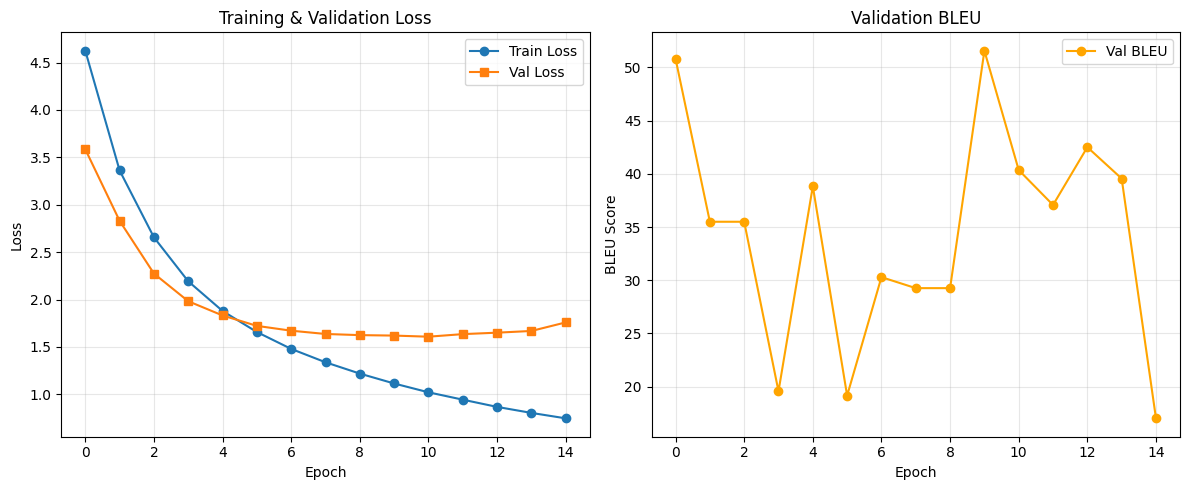


=== 翻译示例 ===
英文: A man in a blue shirt is standing on a ladder .
德文: ein mann in blauem hemd steht auf einer leiter und wird von einem <UNK>

英文: Two dogs are running in the grass .
德文: zwei hunde rennen im gras mit <UNK>

英文: A little girl is eating a cake .
德文: ein kleines mädchen isst einen kuchen mit <UNK>



In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm
from datasets import load_dataset
import sacrebleu

# =============================================================================
# 1. 超参数配置
# =============================================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")

# 数据配置
SRC_LANG = 'en'
TGT_LANG = 'de'
MAX_SEQ_LEN = 50
MAX_VOCAB_SIZE = 8000

# 模型配置（小模型快速验证）
d_model = 256
num_layers = 3
num_heads = 8
d_ff = 1024
dropout = 0.1

# 训练配置
batch_size = 64
epochs = 15
lr = 5e-4

# 特殊token
PAD_TOKEN = '<PAD>'
SOS_TOKEN = '<SOS>'
EOS_TOKEN = '<EOS>'
UNK_TOKEN = '<UNK>'
PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3

# =============================================================================
# 2. 加载数据集 & 构建词汇表
# =============================================================================
print("正在加载Multi30k数据集...")
dataset = load_dataset("bentrevett/multi30k")
train_data = dataset['train']
val_data = dataset['validation']
test_data = dataset['test']

# 简单分词：小写+空格切分
def tokenize(text: str) -> list[str]:
    return text.lower().strip().split()

# 构建词汇表
def build_vocab(data, lang: str, max_size: int) -> tuple[dict, dict]:
    word_freq = {}
    for item in data:
        for word in tokenize(item[lang]):
            word_freq[word] = word_freq.get(word, 0) + 1

    # 按词频排序，取前max_size个
    sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
    words = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN] + [w for w, _ in sorted_words[:max_size-4]]

    word2idx = {w: i for i, w in enumerate(words)}
    idx2word = {i: w for i, w in enumerate(words)}
    return word2idx, idx2word

print("正在构建词汇表...")
src_word2idx, src_idx2word = build_vocab(train_data, SRC_LANG, MAX_VOCAB_SIZE)
tgt_word2idx, tgt_idx2word = build_vocab(train_data, TGT_LANG, MAX_VOCAB_SIZE)
src_vocab_size = len(src_word2idx)
tgt_vocab_size = len(tgt_word2idx)
print(f"源语言词汇表大小: {src_vocab_size}")
print(f"目标语言词汇表大小: {tgt_vocab_size}")

# =============================================================================
# 3. 数据集与数据加载器
# =============================================================================
class TranslationDataset(Dataset):
    def __init__(self, data, src_lang, tgt_lang, src_word2idx, tgt_word2idx, max_len):
        self.data = data
        self.src_lang = src_lang
        self.tgt_lang = tgt_lang
        self.src_word2idx = src_word2idx
        self.tgt_word2idx = tgt_word2idx
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        src_text = self.data[idx][self.src_lang]
        tgt_text = self.data[idx][self.tgt_lang]

        # 转索引，截断超长序列
        src_seq = [self.src_word2idx.get(w, UNK_IDX) for w in tokenize(src_text)][:self.max_len-2]
        tgt_seq = [self.tgt_word2idx.get(w, UNK_IDX) for w in tokenize(tgt_text)][:self.max_len-2]

        # 源序列加EOS，目标序列输入加SOS、标签加EOS
        src_seq = src_seq + [EOS_IDX]
        tgt_input = [SOS_IDX] + tgt_seq
        tgt_output = tgt_seq + [EOS_IDX]

        return (
            torch.tensor(src_seq, dtype=torch.long),
            torch.tensor(tgt_input, dtype=torch.long),
            torch.tensor(tgt_output, dtype=torch.long)
        )

def collate_fn(batch):
    src_batch, tgt_in_batch, tgt_out_batch = zip(*batch)

    # 动态padding
    src_padded = nn.utils.rnn.pad_sequence(src_batch, batch_first=True, padding_value=PAD_IDX)
    tgt_in_padded = nn.utils.rnn.pad_sequence(tgt_in_batch, batch_first=True, padding_value=PAD_IDX)
    tgt_out_padded = nn.utils.rnn.pad_sequence(tgt_out_batch, batch_first=True, padding_value=PAD_IDX)

    # 源padding mask [batch, 1, 1, src_len]
    src_mask = (src_padded != PAD_IDX).unsqueeze(1).unsqueeze(2)

    # 目标mask：下三角 + padding
    tgt_len = tgt_in_padded.size(1)
    look_ahead_mask = torch.tril(torch.ones(tgt_len, tgt_len, dtype=torch.bool))
    tgt_padding_mask = (tgt_in_padded != PAD_IDX).unsqueeze(1).unsqueeze(2)
    tgt_mask = look_ahead_mask & tgt_padding_mask

    return src_padded, tgt_in_padded, tgt_out_padded, src_mask, tgt_mask

# 创建数据加载器
train_dataset = TranslationDataset(train_data, SRC_LANG, TGT_LANG, src_word2idx, tgt_word2idx, MAX_SEQ_LEN)
val_dataset = TranslationDataset(val_data, SRC_LANG, TGT_LANG, src_word2idx, tgt_word2idx, MAX_SEQ_LEN)
test_dataset = TranslationDataset(test_data, SRC_LANG, TGT_LANG, src_word2idx, tgt_word2idx, MAX_SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

# =============================================================================
# 4. Transformer 模型定义
# =============================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 500, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.pe[:x.size(0)]
        return self.dropout(x)

def scaled_dot_product_attention(query, key, value, mask=None):
    d_k = query.size(-1)
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)
    attn_weights = F.softmax(scores, dim=-1)
    output = torch.matmul(attn_weights, value)
    return output, attn_weights

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_k = d_model // num_heads
        self.num_heads = num_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.attn_weights = None

    def forward(self, q, k, v, mask=None):
        batch_size = q.size(0)
        query = self.w_q(q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        key = self.w_k(k).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        value = self.w_v(v).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        attn_output, self.attn_weights = scaled_dot_product_attention(query, key, value, mask)
        attn_output = attn_output.transpose(1, 2).contiguous().view(batch_size, -1, self.num_heads * self.d_k)
        return self.w_o(attn_output)

class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.linear2(self.dropout(self.activation(self.linear1(x))))

class EncoderLayer(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        attn_output = self.self_attn(x, x, x, mask)
        x = self.norm1(x + self.dropout1(attn_output))
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_output))
        return x

class DecoderLayer(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.cross_attn = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(self, x, enc_output, self_mask=None, cross_mask=None):
        attn_output = self.self_attn(x, x, x, self_mask)
        x = self.norm1(x + self.dropout1(attn_output))
        cross_output = self.cross_attn(x, enc_output, enc_output, cross_mask)
        x = self.norm2(x + self.dropout2(cross_output))
        ff_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout3(ff_output))
        return x

class Encoder(nn.Module):
    def __init__(self, vocab_size, d_model, num_layers, num_heads, d_ff, max_len=500, dropout=0.1):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.layers = nn.ModuleList([EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.d_model = d_model

    def forward(self, x, mask=None):
        x = self.token_emb(x) * math.sqrt(self.d_model)
        x = x.transpose(0, 1)
        x = self.pos_enc(x)
        x = x.transpose(0, 1)
        for layer in self.layers:
            x = layer(x, mask)
        return x

class Decoder(nn.Module):
    def __init__(self, vocab_size, d_model, num_layers, num_heads, d_ff, max_len=500, dropout=0.1):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.layers = nn.ModuleList([DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.d_model = d_model

    def forward(self, x, enc_output, self_mask=None, cross_mask=None):
        x = self.token_emb(x) * math.sqrt(self.d_model)
        x = x.transpose(0, 1)
        x = self.pos_enc(x)
        x = x.transpose(0, 1)
        for layer in self.layers:
            x = layer(x, enc_output, self_mask, cross_mask)
        return x

class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model=512, num_layers=6, num_heads=8, d_ff=2048, max_len=500, dropout=0.1):
        super().__init__()
        self.encoder = Encoder(src_vocab_size, d_model, num_layers, num_heads, d_ff, max_len, dropout)
        self.decoder = Decoder(tgt_vocab_size, d_model, num_layers, num_heads, d_ff, max_len, dropout)
        self.final_linear = nn.Linear(d_model, tgt_vocab_size)
        self._init_parameters()

    def _init_parameters(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(self, src, tgt, src_mask=None, tgt_mask=None, cross_mask=None):
        enc_out = self.encoder(src, src_mask)
        dec_out = self.decoder(tgt, enc_out, self_mask=tgt_mask, cross_mask=cross_mask)
        output = self.final_linear(dec_out)
        return output

# =============================================================================
# 5. 实例化模型、损失、优化器
# =============================================================================
model = Transformer(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    d_model=d_model,
    num_layers=num_layers,
    num_heads=num_heads,
    d_ff=d_ff,
    max_len=MAX_SEQ_LEN,
    dropout=dropout
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.98), eps=1e-9)

# 记录训练过程
train_losses = []
val_losses = []
val_bleus = []

# =============================================================================
# 6. 训练与验证函数
# =============================================================================
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    for src, tgt_in, tgt_out, src_mask, tgt_mask in tqdm(loader, desc="训练中"):
        src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
        src_mask, tgt_mask = src_mask.to(device), tgt_mask.to(device)

        optimizer.zero_grad()
        output = model(src, tgt_in, src_mask=src_mask, tgt_mask=tgt_mask, cross_mask=src_mask)
        loss = criterion(output.reshape(-1, tgt_vocab_size), tgt_out.reshape(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)

def val_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for src, tgt_in, tgt_out, src_mask, tgt_mask in tqdm(loader, desc="验证中"):
            src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
            src_mask, tgt_mask = src_mask.to(device), tgt_mask.to(device)

            output = model(src, tgt_in, src_mask=src_mask, tgt_mask=tgt_mask, cross_mask=src_mask)
            loss = criterion(output.reshape(-1, tgt_vocab_size), tgt_out.reshape(-1))
            total_loss += loss.item()
    return total_loss / len(loader)

# =============================================================================
# 7. BLEU 评估函数
# =============================================================================
def translate_sentence(model, src_sentence: str, device, max_len: int = 50) -> str:
    """自回归翻译单个句子"""
    model.eval()
    # 源句子处理
    src_seq = [src_word2idx.get(w, UNK_IDX) for w in tokenize(src_sentence)][:max_len-2]
    src_seq = src_seq + [EOS_IDX]
    src = torch.tensor(src_seq, dtype=torch.long).unsqueeze(0).to(device)
    src_mask = (src != PAD_IDX).unsqueeze(1).unsqueeze(2).to(device)

    # 编码器一次性计算
    enc_out = model.encoder(src, src_mask)

    # 解码起始
    tgt = torch.tensor([[SOS_IDX]], dtype=torch.long).to(device)

    for _ in range(max_len):
        tgt_len = tgt.size(1)
        look_ahead_mask = torch.tril(torch.ones(tgt_len, tgt_len, dtype=torch.bool)).to(device)
        tgt_mask = look_ahead_mask.unsqueeze(0).unsqueeze(0)

        dec_out = model.decoder(tgt, enc_out, self_mask=tgt_mask, cross_mask=src_mask)
        output = model.final_linear(dec_out)

        next_token = output[:, -1, :].argmax(dim=-1).item()
        if next_token == EOS_IDX:
            break

        tgt = torch.cat([tgt, torch.tensor([[next_token]], dtype=torch.long).to(device)], dim=1)

    # 用 view(-1) 强制展平为一维，避免标量问题
    words = [tgt_idx2word[i] for i in tgt.view(-1).tolist()]
    # 去掉SOS，返回最终字符串
    return ' '.join(words[1:])

def calculate_bleu(model, dataset, device) -> float:
    """计算整个数据集的BLEU分数"""
    hypotheses = []
    references = []

    for item in tqdm(dataset, desc="计算BLEU中"):
        src_text = item[SRC_LANG]
        tgt_text = item[TGT_LANG]

        pred = translate_sentence(model, src_text, device)
        hypotheses.append(pred)
        references.append([tgt_text.lower()])

    bleu = sacrebleu.corpus_bleu(hypotheses, references)
    return bleu.score

# =============================================================================
# 8. 开始训练
# =============================================================================
print("\n开始训练...")
for epoch in range(epochs):
    print(f"\n=== 第 {epoch+1}/{epochs} 轮 ===")
    train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = val_epoch(model, val_loader, criterion, device)
    val_bleu = calculate_bleu(model, val_data, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_bleus.append(val_bleu)

    print(f"训练损失: {train_loss:.4f} | 验证损失: {val_loss:.4f} | 验证BLEU: {val_bleu:.2f}")

# =============================================================================
# 9. 测试集最终评估
# =============================================================================
test_loss = val_epoch(model, test_loader, criterion, device)
test_bleu = calculate_bleu(model, test_data, device)
print(f"\n=== 测试集最终结果 ===")
print(f"测试损失: {test_loss:.4f} | 测试BLEU: {test_bleu:.2f}")

# =============================================================================
# 10. 绘制训练曲线
# =============================================================================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Val Loss', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(val_bleus, label='Val BLEU', marker='o', color='orange')
plt.xlabel('Epoch')
plt.ylabel('BLEU Score')
plt.title('Validation BLEU')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('transformer_translation_curve.png', dpi=150)
plt.show()

# =============================================================================
# 11. 翻译示例
# =============================================================================
print("\n=== 翻译示例 ===")
examples = [
    "A man in a blue shirt is standing on a ladder .",
    "Two dogs are running in the grass .",
    "A little girl is eating a cake ."
]
for eng in examples:
    deu = translate_sentence(model, eng, device)
    print(f"英文: {eng}")
    print(f"德文: {deu}\n")